# Örnekler

# Basit kesirlere ayırma

## Ön çalışma Örnek 7

In [3]:
# import the necessary libraries
import numpy as np # for using basic array functions
import matplotlib.pyplot as plt # for this example, it may not be necessary
# the main package for signal processing is called "scipy" and we will use "signal"
import scipy.signal as sgnl
# alternative syntax: from scipy import signal as sgnl

In [11]:
z = np.array([0])
p = np.array([1.0/4, 1.0/2]) 
b, a = sgnl.zpk2tf(z, p, 1) 
b,a

(array([1., 0.]), array([ 1.   , -0.75 ,  0.125]))

In [9]:
# alternative way to expand a product:
a = sgnl.convolve(np.array([1, -1/4]),np.array([1, -1/2]))
print(a)

[ 1.    -0.75   0.125]


Now that it is in a more convenient format (in the transfer function form), we can compute the coefficients of the partial fraction form as follows:

In [12]:
# given the coeffs of numerator, i.e. b(z) and the coeffs of denominator a(z), # we do the partial fraction expansion by:
r, p, k = sgnl.residuez(b,a) #
print(r,p,k)
# to check the correctness of the polynomial roots (i.e. p's) we can use
poless = np.roots(a) # returns the polynomial coefficients of the denominator

[-1.  2.] [0.25 0.5 ] []


In [19]:
def get_z_transform_from_residuez(r,p,k,floating_point = 2):
    xz = ""
    for i in range(len(p)):
        count = 1
        if (i>0 and p[i] == p[i-1] ):
            count += 1
        else:
            count = 1
        xz += "({:.{}f})/(1-({:.{}f})z^-1)^{}".format(r[i],floating_point,p[i],floating_point,count)
        if i < len(p)-1:
            xz += " + "
    for i in range(len(k)):
        if i == 0:
            xz += " + "
        xz += "({:.{}f})z^-{}".format(k[i],floating_point,i)
        if i < len(k)-1:
            xz += " + "
    return xz
xz = get_z_transform_from_residuez(r,p,k)
print(xz)
    

(-1.00)/(1-0.25z^-1) + (2.00)/(1-0.50z^-1)


### zpk2tf nedir

#### Örnek 1

In [20]:
# Öncelikle gerekli kütüphaneleri yükleyiniz
import numpy as np
import scipy.signal as sgnl

In [21]:
k = 5 # kazanç bu sistem fonksiyonu için 5'tir
z = np.array([-0.5, -0.5]) # iki sıfır (zero)   @ z= -1/2, -1/2
p = np.array([0, 1.0/3, 1.0/4]) # üç kutup (pole) @ z=0, 1/3, 1/4
b, a = sgnl.zpk2tf(z, p, k) 
print("pay, b:", b) 
print("payda: a:", a)

pay, b: [5.   5.   1.25]
payda: a: [ 1.         -0.58333333  0.08333333  0.        ]


In [37]:
def represent_z_tf_positive(b,a, floating_point = 2):
    xz = ""
    for i in range(len(b)):
        xz += "({:.{}f})z^{}".format(b[i],floating_point,len(b)-i-1)
        if i < len(b)-1:
            xz += " + "
    xz += "\n"
    for i in range(len(a)):
        xz += "({:.{}f})z^{}".format(a[i],floating_point,len(a)-i-1)
        if i < len(a)-1:
            xz += " + "
    return xz
print("\nxz positive:")
xz_positive = represent_z_tf_positive(b,a,7)
print(xz_positive)
def represent_z_tf_negative(b,a,floating_point = 2):
    if len(b) < len(a):
        b = np.append(np.zeros(len(a)-len(b)),b)
    xz = ""
    for i in range(len(b)):
        xz += "({:.{}f})z^-{}".format(b[i],floating_point,i)
        if i < len(b)-1:
            xz += " + "
    xz += "\n"
    for i in range(len(a)):
        xz += "({:.{}f})z^-{}".format(a[i],floating_point,i)
        if i < len(a)-1:
            xz += " + "
    return xz , b , a
print("\nxz Negative: ")
xz_negative = represent_z_tf_negative(b,a,7)
print(xz_negative)


xz positive:
(5.0000000)z^2 + (5.0000000)z^1 + (1.2500000)z^0
(1.0000000)z^3 + (-0.5833333)z^2 + (0.0833333)z^1 + (0.0000000)z^0

xz Negative: 
(5.0000000)z^-1 + (1.2500000)z^-2
(1.0000000)z^-0 + (-0.5833333)z^-1 + (0.0833333)z^-2 + (0.0000000)z^-3


#### Örnek 2

In [42]:
k = 5 # kazanç bu sistem fonksiyonu için 5'tir
z = np.array([]) # hiç sıfır yok
p = np.array([1.0/3]) # bir kutup (pole) @ z= 1/3
b, a = sgnl.zpk2tf(z, p, k) 
print("pay, b:", b) 
print("payda: a:", a)
print("\nxz positive:")
xz_positive = represent_z_tf_positive(b,a,7)
print(xz_positive)

pay, b: [5.]
payda: a: [ 1.         -0.33333333]

xz positive:
(5.0000000)z^0
(1.0000000)z^1 + (-0.3333333)z^0


# Kuvvet Serisine açma

## Ön Çalışma Örnek 8

In [43]:
# import the necessary libraries
import numpy as np # for using basic array functions
import matplotlib.pyplot as plt # for this example, it may not be necessary
# the main package for signal processing is called "scipy" and we will use "signal"
import scipy.signal as sgnl

In [48]:
num = np.array([1,0,0]) # we add zeros to match the size of num and 
denum = np.array([1, -3.0/4, 1.0/8]) # coeffs of denum
n, x = sgnl.dimpulse((num, denum, 1),x0=0, n=10) 
print(x)

(array([[1.        ],
       [0.75      ],
       [0.4375    ],
       [0.234375  ],
       [0.12109375],
       [0.06152344],
       [0.03100586],
       [0.01556396],
       [0.00779724],
       [0.00390244]]),)


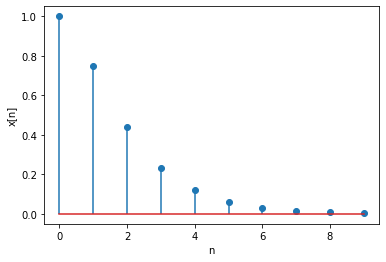

In [50]:
plt.stem(n, np.squeeze(x))
plt.xlabel('n')
plt.ylabel('x[n]')
plt.show()

## Örnek 9

In [51]:
# import the necessary libraries
import numpy as np # for using basic array functions
import matplotlib.pyplot as plt # for this example, it may not be necessary
# the main package for signal processing is called "scipy" and we will use "signal"
import scipy.signal as sgnl
# alternative syntax: from scipy import signal as sgnl

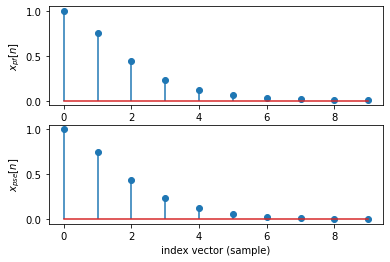

In [54]:
n = np.arange(0,10,1)
xpf = -(1.0/4)**n + 2*(1.0/2)**n
num = np.array([1, 0, 0])
denum = np.array([1, -3.0/4, 1.0/8])
# define the index vector for 10 points
# result of Ornek-7
     # we add zeros to match the size of num an
     # coeffs of denum
n1, xpse = sgnl.dimpulse((num, denum, 1),x0=0, n=10) 
xpse = np.squeeze(xpse)
plt.subplot(2,1,1), plt.stem(n, xpf), plt.ylabel('$x_{pf}[n]$') 
plt.subplot(2,1,2), plt.stem(n, xpse), plt.ylabel('$x_{pse}[n]$') 
plt.xlabel('index vector (sample)')
plt.show()


We have defined the outputs of the examples, now by plotting on the same figure, we will confirm that these two sequences are the same, as expected.as can be seen in the figure, the samples are the same for the two signals, therefore, we have confirmed that both of the methods result in the same time domain signal, but in different forms.

## Örnek 10

This example implements obtaining the frequency response of a discrete time system given in its Z-transform, and applying an input signal to it to calculate the output of the system.

In [55]:
# import the necessary libraries
import numpy as np # for using basic array functions
import matplotlib.pyplot as plt # for this example, it may not be necessary
# the main package for signal processing is called "scipy" and we will use "signal"
import scipy.signal as sgnl
# alternative syntax: from scipy import signal as sgnl

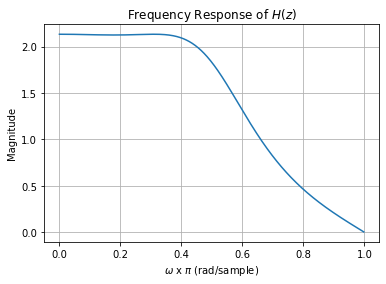

In [56]:
zeros = np.array([-1]) # observe that the numerator can be defined as transf 
poles = np.array([1j/2, -1j/2, 1.0/4])
w, H = sgnl.freqz_zpk(zeros, poles, 1)
plt.plot(w/np.pi, abs(H)) # plot the magnitude in logarithmic scale with blue 
plt.title('Frequency Response of $H(z)$')
plt.ylabel('Magnitude'), plt.xlabel('$\omega$ x $\pi$ (rad/sample)')
plt.grid()

Now, we will convert the system into the transfer function form and repeat the same steps.

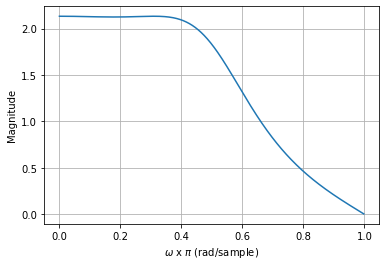

In [57]:
num, denum = sgnl.zpk2tf(zeros, poles, 1) # will return the coefficients b and a, r 
w1, H_tf = sgnl.freqz(num, denum)
plt.figure()
plt.plot(w1/np.pi, abs(H_tf)) # plot the magnitude in logarithmic scale with b plt.title('Frequency Response of $H(z)$')
plt.ylabel('Magnitude'), plt.xlabel('$\omega$ x $\pi$ (rad/sample)')
plt.grid()

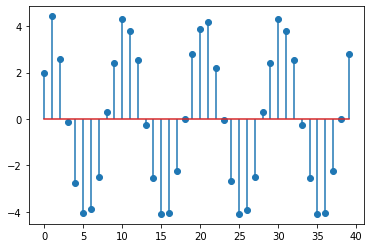

In [59]:
n = np.arange(0, 40, 1) # define the index vector
xn = 2*np.cos(0.2*np.pi*n) + np.sin(0.9*np.pi*n) # define the input signal
yn = sgnl.lfilter(num, denum, xn) 
plt.figure()
plt.stem(n, yn)
plt.show()

## Örnek 11

In [60]:
# import the necessary libraries
import numpy as np              # for using basic array functions
import matplotlib.pyplot as plt # for this example, it may not be necessary

# the main package for signal processing is called "scipy" and we will use "signal" sub-package
import scipy.signal as sgnl 
# alternative syntax: from scipy import signal as sgnl

def zplane(b,a):

	# Input: numerator and denominator coefficients:
	zeross,poless,k = sgnl.tf2zpk(b, a)
	if not zeross.size:
		zeross = np.zeros(len(poless))
		
	if not poless.size:
		poless = np.zeros(len(zeross))

	tol = 1e-4

	real_p = np.real(poless).copy()
	real_z = np.real(zeross).copy()
	imag_p = np.imag(poless).copy()
	imag_z = np.imag(zeross).copy()

	if not real_z.size:
		real_z[abs(real_z) < tol] = 0
	if not imag_z.size:
		imag_z[abs(imag_z) < tol] = 0
	if not real_p.size:
		real_p[abs(real_p) < tol] = 0
	if not imag_p.size:
		imag_p[abs(imag_p) < tol] = 0

	z = np.round(real_z,2) + 1j*np.round(imag_z,2)
	p = np.round(real_p,2) + 1j*np.round(imag_p,2)

	# plot the unit circle
	N = 128
	m = np.arange(0,N,1)
	unitCircle = np.exp(1j*m*2*np.pi/N)

	plt.figure()
	plt.plot(np.real(unitCircle), np.imag(unitCircle), 'b--', linewidth=0.3)
	plt.xlabel('Real Part'), plt.ylabel('Imaginary Part')

	# calculate the plot limits
	Cz, z_counts = np.unique(z, return_counts=True)
	Cp, p_counts = np.unique(p, return_counts=True)

	zz = [idx1 for idx1, valz in enumerate(z_counts) if valz > 1]
	pp = [idx2 for idx2, valp in enumerate(p_counts) if valp > 1]
	zval = z_counts[zz]
	pval = p_counts[pp]
	zs = Cz[zz]
	ps = Cp[pp]

	real_roots = np.concatenate((np.real(p),np.real(z)))
	imag_roots = np.concatenate((np.imag(p),np.imag(z)))

	# adjust plot limits
	xlower = min(-1, min(real_roots)) - 0.3
	xupper = max(1,  max(real_roots)) + 0.3
	ylower = min(-1, min(imag_roots)) - 0.3
	yupper = max(1,  max(imag_roots)) + 0.3
	plt.xlim(xlower, xupper), plt.ylim(ylower, yupper)

	# plot axes
	Xaxis = np.arange(xlower, xupper, 0.1)
	Yaxis = np.arange(ylower, yupper, 0.1)
	plt.plot(np.real(Xaxis), np.imag(Xaxis), 'b--', linewidth=0.3)
	plt.plot(np.imag(Yaxis), np.real(Yaxis), 'b--', linewidth=0.3)

	# plot poles and zeros
	plt.plot(np.real(z), np.imag(z), 'ro',  markerfacecolor = 'none')
	plt.plot(np.real(p), np.imag(p), 'rx')

	if zz:
		txtz = str(zval)[1:-1]
		plt.annotate(txtz, xy=(np.real(zs)+0.1,np.imag(zs)+0.1))
		
	if pp:
		txtp = str(pval)[1:-1]
		plt.annotate(txtp, xy=(np.real(ps)+0.1,np.imag(ps)+0.1))

	plt.grid()
	plt.show()


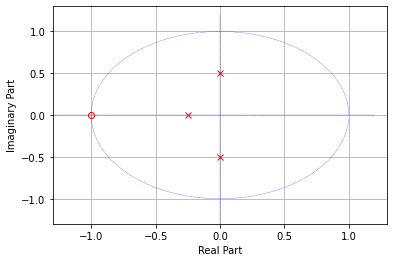

In [62]:
zeross = np.array([-1])
poless = np.array([-1j/2, 1j/2, -1/4]) 
k = 1
b, a = sgnl.zpk2tf(zeross,poless,k) 
zplane(b,a)

<Figure size 432x288 with 0 Axes>

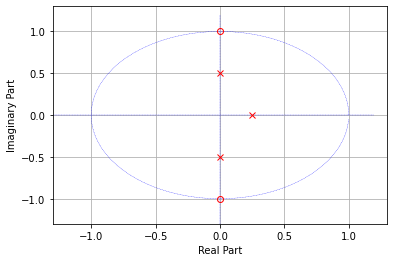

In [65]:
num = np.array([1, 0, 1]) # note that the coeff of z^(-1) term is zero. denum = np.array([1, -1.0/2])
plt.figure() ,zplane(num, denum)
plt.show()

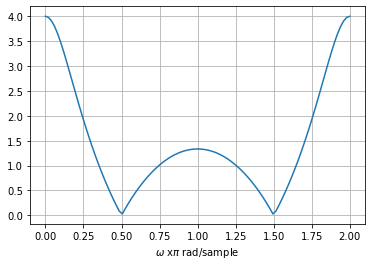

In [68]:
# Now, we define the frequency response as:
w = np.linspace(0, 2*np.pi, 100)
Hw = (1+np.exp(-2*1j*w))/(1-(1/2)*np.exp(-1j*w))
# alternatively, we could use the sgnl.freqz_zpk() function to calculate the Frequen # or sgnl.freqz() function to calculate from the coefficients.
Hw_abs = abs(Hw) 
plt.figure() 
plt.plot(w/np.pi, Hw_abs)
plt.grid()
plt.xlabel('$\omega$ x$\pi$ rad/sample')
plt.show()

# Ödev 1

1) Aşağıda bir DZD sistem fark denklemi olarak verilmiştir. Buna göre, aşağıdaki soruları cevaplayinı:
$$
y[n]=\frac{1}{2} y[n-1]-4 y[n-2]+2 y[n-3]+x[n]+\frac{2}{3} x[n-1]+\frac{1}{9} x[n-2]
$$

a) Sistem fonksiyonu $H(z)^{\prime} y i$ el ile hesaplayınız. <br>
a1) Girişe dürtü işareti vererek sistemin çıkışını bularak elde ediniz. <br>
a2) Ters z dönüşümünü hesaplayarak elde ediniz.<br>
İki farklı yöntemle elde ettiğiniz sonuçları karşılaştırınız.<br>
b) Sistemin kutup-sıfır diyagramını Python ile çiziniz.<br>
c) ROC bölgesini şu iki durum için ayrı ayrı belirleyiniz:<br>
c.1. eğer $h[n]=0, n<0$.<br>
c.2. eğer sistemin Fourier dönüşümü varsa.<br>
d) Sistemin dürtü cevabını (c.1) durumu için bulunuz. Dürtü cevabını $n=0,1,2, \ldots, 30$ için çizdiriniz ve sistemin kararlılığını yorumlayınız. (Bahsi geçen ters dönüşüm yöntemlerinden herhangi birini kullanabilirsiniz.)<br>
e) Bu sistem aynı anda hem kararlı hem de nedensel olabilir mi? Açıklayınız. Eğer cevabınız hayır ise, bu sistemi hem kararlı hem de nedensel yapabilmek için nasıl bir işlem uygulanmalıdır, matematiksel olarak gösteriniz.<br>
f) Bir önceki (e) şıkkında bulduğunuz sistemin kutup-sıfır diyagramı ve dürtü cevabını bulunuz ve çizdiriniz (OnCalismaOrnek10.ipynb'daki lfilter() fonksiyonunu kullanıp, giriş işaretini de dürtü olarak tanımlayabilirsiniz). Sistemin kutup konumlarının dürtü cevabı üzerindeki etkisini gözleyiniz. Kutupların birim çembere göre konumu, reel ve imajiner eksenlerde bulunduğu bölge vb. göz önünde bulundurarak gözlemlerinizi raporlayınız.


## 1-a)

### 1-a-a1)

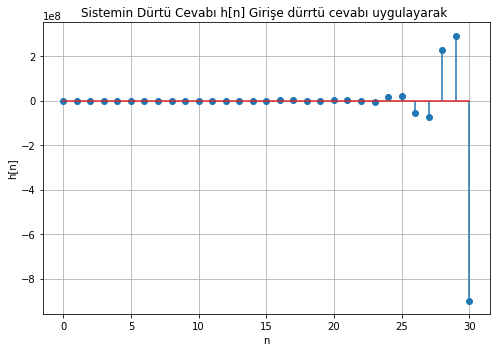

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
def dirac(n):
    return np.where(n == 0, 1, 0)
# Sistem denkleminin katsayılarını tanımlayalım
a = [1, -1/2, 4, -2]
b = [1, 2/3, 1/9]

# Dürtü işaretini tanımlayalım
n = np.arange(0, 31)
delta = dirac(n)


# Sistemin cevabını hesaplayalım
h = signal.lfilter(b, a, delta)

# Sistemin cevabını çizdirelim
plt.figure( figsize=(7, 5))
plt.stem(n, h)
plt.xlabel('n')
plt.ylabel('h[n]')
plt.title('Sistemin Dürtü Cevabı h[n] Girişe dürrtü cevabı uygulayarak ')
plt.grid(True)
plt.tight_layout()
plt.show()


### 1-a-a2)

$\begin{aligned} & x\left[n_{-} n_0\right] \stackrel{z}{\longleftrightarrow} z^{-n_0} X(z) \\ & Y(z)=\frac{1}{2} z^{-1} Y(z)-4 z^{-2} Y(z)+2 z^{-3} Y(z)+X(z)+\frac{2}{3} z^{-1} X(z)+\frac{1}{9} z^{-2} X(z) \\ & \left(1-\frac{1}{2} z^{-1}+4 z^{-2}-2 z^{-3}\right) Y(z)=\left(1+\frac{2}{3} z^{-1}+\frac{1}{9} z^{-2}\right) X(z) \\ & H(z)=\frac{Y(z)}{X(z)}=\frac{\left(1+\frac{2}{3} z^{-1}+\frac{1}{9} z^{-2}\right)}{\left(1-\frac{1}{2} z^{-1}+4 z^{-2}-2 z^{-3}\right)} \\ & \quad=\frac{\left(z^3+\frac{2}{3} z^2+\frac{1}{9} z^1\right)}{\left(z^3-\frac{1}{2} z^2+4 z-2\right)}\end{aligned}$

In [3]:
def get_z_transform_from_residuez(r,p,k,floating_point = 2):
    xz = ""
    for i in range(len(p)):
        count = 1
        if (i>0 and p[i] == p[i-1] ):
            count += 1
        else:
            count = 1
        xz += "({:.{}f})/(1-({:.{}f})z^-1)^{}".format(r[i],floating_point,p[i],floating_point,count)
        if i < len(p)-1:
            xz += " + "
    for i in range(len(k)):
        if i == 0:
            xz += " + "
        xz += "({:.{}f})z^-{}".format(k[i],floating_point,i)
        if i < len(k)-1:
            xz += " + "
    return xz
def represent_z_tf_positive(b,a, floating_point = 2):
    xz = ""
    for i in range(len(b)):
        xz += "({:.{}f})z^{}".format(b[i],floating_point,len(b)-i-1)
        if i < len(b)-1:
            xz += " + "
    xz += "\n"
    for i in range(len(a)):
        xz += "({:.{}f})z^{}".format(a[i],floating_point,len(a)-i-1)
        if i < len(a)-1:
            xz += " + "
    return xz

def represent_z_tf_negative(b,a,floating_point = 2):
    if len(b) < len(a):
        b = np.append(np.zeros(len(a)-len(b)),b)
    xz = ""
    for i in range(len(b)):
        xz += "({:.{}f})z^-{}".format(b[i],floating_point,i)
        if i < len(b)-1:
            xz += " + "
    xz += "\n"
    for i in range(len(a)):
        xz += "({:.{}f})z^-{}".format(a[i],floating_point,i)
        if i < len(a)-1:
            xz += " + "
    return xz , b , a

(0.16+0.00j)/(1-(0.50+0.00j)z^-1)^1 + (0.42-0.27j)/(1-(0.00+2.00j)z^-1)^1 + (0.42+0.27j)/(1-(0.00-2.00j)z^-1)^1


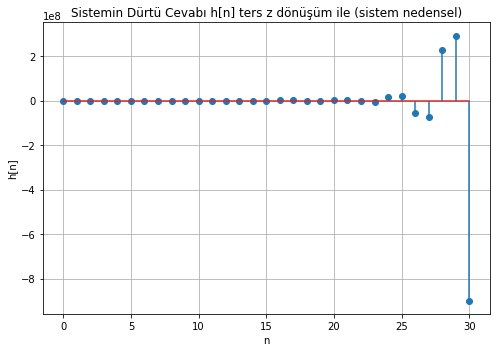

In [4]:
import scipy.signal as sgnl
import numpy as np
import matplotlib.pyplot as plt
import zplane
b_negative = np.array([1, 2/3, 1/9, 0])
a_negative = np.array([1, -1/2, 4, -2])
r, p, k = sgnl.residuez(b_negative, a_negative) 
xz = get_z_transform_from_residuez(r,p,k,2)
print(xz)
def u(n):
    return np.where(n >= 0, 1, 0)
n = np.arange(0,31)
hn = 0
for i in range(len(r)):
    hn += np.real(r[i] * p[i]**n) * u(n)
plt.figure( figsize=(7, 5))
plt.stem(n, hn)
plt.xlabel('n')
plt.ylabel('h[n]')
plt.title('Sistemin Dürtü Cevabı h[n] ters z dönüşüm ile (sistem nedensel)')
plt.grid(True)
plt.tight_layout()
plt.show()    

### El ile

$$
\begin{aligned}
& y[n]=\frac{1}{2} y[n-1]-4 y[n-2]+2 y[n-3]+x[n]+\frac{2}{3} x[n-1]+\frac{1}{9} x[n-2] \\
& x\left[n-n_{0}\right] \stackrel{z}{ } z^{-n_{0}} X(z) \\
& Y(z)=\frac{1}{2} z^{-1} Y(z)-4 z^{-2} Y(z)+2 z^{-3} Y(z)+X(z)+\frac{2}{3} z^{-1} X(z)+\frac{1}{9} z^{-2} X(z) \\
& \left(1-\frac{1}{2} z^{-1}+4 z^{-2}-2 z^{-3}\right) Y(z)=\left(1+\frac{2}{3} z^{-1}+\frac{1}{9} z^{-2}\right) X(z) \\
& H(z)=\frac{Y(z)}{X(z)}=\frac{\left(1+\frac{2}{3} z^{-1}+\frac{1}{9} z^{-2}\right)}{\left(1-\frac{1}{2} z^{-1}+4 z^{-2}-2 z^{-3}\right)} \\
& =\frac{\left(z^{3}+\frac{2}{3} z^{2}+\frac{1}{9} z^{1}\right)}{\left(z^{3}-\frac{1}{2} z^{2}+4 z-2\right)}
\end{aligned}
$$



$$
H(z)=\frac{0,16}{1-0,52^{-1}}+\frac{(0,42-0,27 j)}{1-2 j z^{-1}}+\frac{0,42+0,27 j}{1+2 j 2^{-1}}
$$

From the 2 transform table:

$$
a^{n} u[n] \leftrightarrows \frac{1}{1-a z^{-1}} \quad|z|>|a|
$$

So $h[n]=0,16(0,5)^{n} u[n]+(0,42-0,27 j)(2 j)^{n} u[n]$

$$
+(0,42+0,27 j)(-2 j)^{n}
$$


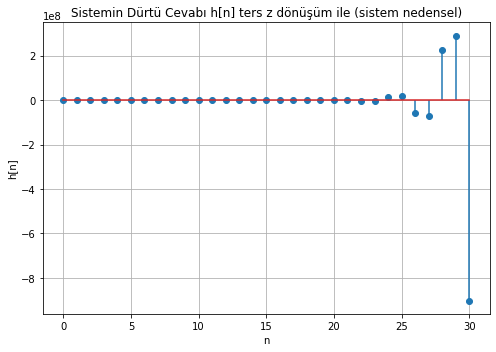

In [8]:
n = np.arange(0, 31)
h = 0.16* ((0.5)**n) * u(n) + (0.42 - 0.27j) *((2j)**n) * u(n) + (0.42 + 0.27j) *((-2j)**n) * u(n)
h_real = np.real(h)
h_imag = np.imag(h)
plt.figure( figsize=(7, 5))
plt.stem(n, h_real)
plt.xlabel('n')
plt.ylabel('h[n]')
plt.title('Sistemin Dürtü Cevabı h[n] ters z dönüşüm ile (sistem nedensel)')
plt.grid(True)
plt.tight_layout()
plt.show()

### Dimpulse ile

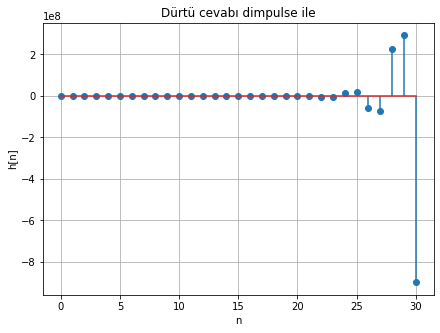

In [10]:
import scipy.signal as sgnl
import numpy as np
import zplane
num = [1, 2/3, 1/9, 0]
denum = [1, -1/2, 4, -2]
n, hn = sgnl.dimpulse((num, denum, 1),x0=0, n=31) 
#plotting the impulse response
plt.figure(figsize=(7, 5))
plt.stem(n, np.squeeze(hn))
plt.title('Dürtü cevabı dimpulse ile')
plt.xlabel('n')
plt.ylabel('h[n]')
plt.grid()
plt.show()



## 1-b)

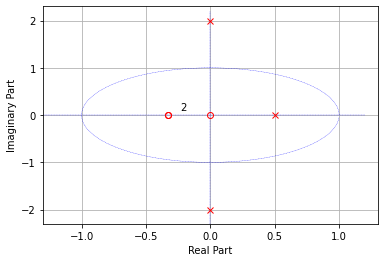

In [11]:
# Sistemin kutuplarını ve sıfırlarını çizdirelim
b = np.array([1, 2/3, 1/9, 0])
a = np.array([1, -1/2, 4, -2])
zplane.zplane(b, a)
plt.show()


## 1-c)
### c.1

eğer h[𝑛] = 0, 𝑛 < 0 . Sistem nedenseldir. Sİstemin nedensel olması için ROC sağ yanlıdır, en dıştaki kutuptan dışarı doğrudur. Bu yüzden $ ROC : |z|>2 $

### c.2

Eğer sistemin Fourier dönüşümü varsa. ROC Birim çemberi içermelidir o zaman $ ROC : 0.5<|z|<2 $

## 1-d)

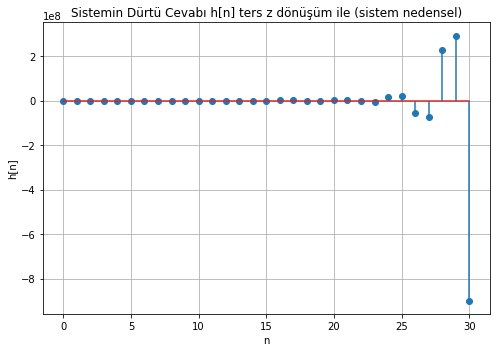

In [7]:
import scipy.signal as sgnl
import numpy as np
import matplotlib.pyplot as plt
import zplane
b_negative = np.array([1, 2/3, 1/9, 0])
a_negative = np.array([1, -1/2, 4, -2])
r, p, k = sgnl.residuez(b_negative, a_negative) 
get_z_transform_from_residuez(r,p,k,5)
def u(n):
    return np.where(n >= 0, 1, 0)
n = np.arange(0,31)
hn = 0
for i in range(len(r)):
    hn += np.real(r[i] * p[i]**n) * u(n)
plt.figure( figsize=(7, 5))
plt.stem(n, hn)
plt.xlabel('n')
plt.ylabel('h[n]')
plt.title('Sistemin Dürtü Cevabı h[n] ters z dönüşüm ile (sistem nedensel)')
plt.grid(True)
plt.tight_layout()
plt.show()    

Sistemin dürtü cevabı gittikçe büyümekte ve sonsuza gitmektedir bu yüzden sistem kararsızdır

## 1-e)

Hayır aynı zamanda nedensel ve kararlı olmaz. Çünkü kararlı olması için birim çemberi içermeli ve nedensel olması için sağ yanlı olmalıdır. Ama birim çemberin sağında kutup olduğundan dolayı aynı zamanda birim çemberi içerip sağ yanlı olamamktadır.

Sistemi aynı zamanda kararlı aynı zamanda nedensel yapmak için birim çemberin dışındaki kutuplardan kurtulmak gerekmektedir. H(z) , (1-2jz^-1) ve (1+2jz^-1) ile çarpılır böylece o kutuplardan kurtulmuş oluruz.


$$
\begin{aligned}
& H(z)\left(1-2 j z^{-1}\right)\left(1+2 j z^{-1}\right) \\ \end{aligned}
$$

$$
\begin{aligned}
H_{\text {new }}(z) & =\frac{\left(1+\frac{2}{3} z^{-1}+\frac{1}{9} z^{-2}\right)\left(1-2 j z^{-1}\right)\left(1+2 j z^{-1}\right)}{\left(1-0,5 z^{-1}\right)\left(1-2 j z^{-1}\right)\left(1+2 j z^{-1}\right)} \\
& =\frac{z^{2}+\frac{2}{3} z+\frac{1}{9}}{z^{2}-0,5 z+0}
\end{aligned}
$$

$$
\begin{aligned}
& H_{\text {new }}(z)=\frac{1}{1-0,5 z^{-1}}+\frac{\frac{2}{3} z^{-1}}{1-0,5 z^{-1}}+\frac{\frac{1}{9} z^{-2}}{1-0,5 z^{-1}} \\
& h[n]=(0,5)^{n} u[n]+\frac{2}{3}(0,5)^{n-1} u[n-1]+\frac{1}{9}(0,5)^{n-2} u[n-2]
\end{aligned}
$$



## 1-f)

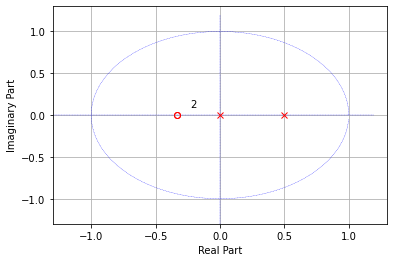

In [19]:
b = np.array([1,2/3,1/9])
a = np.array([1, -0.5,0])
zplane.zplane(b, a)
plt.show()

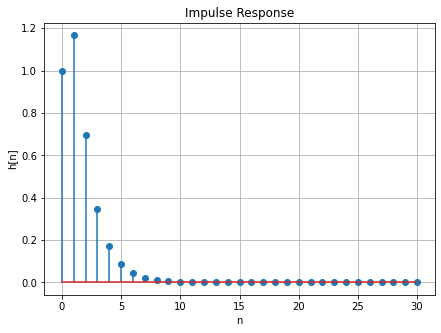

In [25]:

n = np.arange(0, 31)
h = ((0.5)**n) * u(n) + (2/3)*((0.5)**(n-1)) * u(n-1) + (1/9)*((0.5)**(n-2)) * u(n-2)
#plot
plt.figure(figsize=(7, 5))
plt.stem(n, h)
plt.title('Impulse Response')
plt.xlabel('n')
plt.ylabel('h[n]')
plt.grid()
plt.show()